In [36]:
from pathlib import Path
import json
import pandas as pd

parent_dir = Path.cwd().parents[1] 

file_path = parent_dir / "Dataset" / "research_abstracts.json"

with open(file_path, 'r', encoding="utf-8")as f:
    data = json.load(f)

print(data)

data = data["Abstract"]

display(data)

{'DOI': {'0': '10.1155/2021/1071145', '1': '10.1007/s43546-022-00384-2', '2': '10.1002/for.2667', '3': '10.1007/s42973-021-00091-x', '4': '10.1007/s40258-012-0003-z', '5': '10.1136/tc-2021-057232', '6': '10.1016/j.ssresearch.2019.102351', '7': '10.1080/02664763.2020.1732885', '8': '10.1097/01.mlr.0000118873.10396.fc', '9': '10.1016/j.mex.2021.101226', '10': '10.1038/s41598-020-64506-2', '11': '10.1371/journal.pone.0237672', '12': '10.2139/ssrn.3042952', '13': 'https://ssrn.com/abstract=1557280', '14': '10.1016/j.cbrev.2017.01.001', '15': '10.23917/jep.v5i1.4030', '16': '10.1109/cec.2007.4424790', '17': '10.1007/s12197-016-9354-x', '18': '10.1080/1331677x.2017.1314826', '19': '10.1111/j.1467-985x.2012.01061.x', '20': '10.1109/inocon57975.2023.10101073', '21': '10.1109/isitia.2017.8124101', '22': '10.1002/jae.2784', '23': '10.1080/13504850701578835', '24': '10.18356/df5e9f55-en', '25': '10.1162/003465303772815952', '26': '10.2139/ssrn.1016574', '27': '10.17016/ifdp.2003.780', '28': '10.2

{'0': "Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutions and investors better make investment decisions. In this sense, the forecast of inflation rate is of great significance. The existing literature mainly uses linear models such as autoregressive (AR) and vector autoregressive (VAR) models to predict the inflation rate. The nonlinear relationship between variables and the mining of historical data information are relatively lacking. Therefore, the prediction strategies and accuracy of the existing literature need to be improved. The predictive model designed in deep learning can fully mine the nonlinear relationship between variables and process complex long-term time series dynamic information, thereby making up for the deficiencies 

In [37]:
df = pd.Series(data).to_frame(name='Abstract')
display(df)

,Abstract
0,Forward-looking forecasting of the inflation r...
1,Our study examined the disaggregation of infla...
2,This paper develops a dynamic factor model tha...
3,"In this paper, I use a simple SIR Macro model ..."
4,BackgroundGame theory is useful for identifyin...
...,...
1133,Concluding remarksWhile the final version of t...
1134,High-Dimensional Dynamic Factor Models have th...
1135,"Francesca Gino, Erin L. Krupka, Roberto A. Web..."
1136,"Summary EOR projects, notably CO2 floods, are ..."


In [38]:
df = df.drop_duplicates()
print(df['Abstract'].duplicated().sum())

0


In [39]:
df = df.dropna()
print(df['Abstract'].isna().sum())

0


In [40]:
import re

pattern_one = r'[^\w\s]'
pattern_two = r'\s+'

df['clean_Abstract'] = (
    df['Abstract']
    .str.replace(pattern_one, ' ', regex=True)
    .str.replace(pattern_two, ' ', regex=True)
    .str.strip()
)

In [41]:
# Coonvert Clean Abstract to Lowercase

df['clean_Abstract'] = df['clean_Abstract'].apply(str.lower)

In [43]:
df

,Abstract,clean_Abstract
0,Forward-looking forecasting of the inflation r...,forward looking forecasting of the inflation r...
1,Our study examined the disaggregation of infla...,our study examined the disaggregation of infla...
2,This paper develops a dynamic factor model tha...,this paper develops a dynamic factor model tha...
3,"In this paper, I use a simple SIR Macro model ...",in this paper i use a simple sir macro model t...
4,BackgroundGame theory is useful for identifyin...,backgroundgame theory is useful for identifyin...
...,...,...
1133,Concluding remarksWhile the final version of t...,concluding remarkswhile the final version of t...
1134,High-Dimensional Dynamic Factor Models have th...,high dimensional dynamic factor models have th...
1135,"Francesca Gino, Erin L. Krupka, Roberto A. Web...",francesca gino erin l krupka roberto a weber d...
1136,"Summary EOR projects, notably CO2 floods, are ...",summary eor projects notably co2 floods are th...


In [44]:
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
import nltk

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')

lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    words = word_tokenize(text)
    tagged_words = pos_tag(words)

    lemmas = []

    for word, tag in tagged_words:
        if tag.startswith('J'):
            pos = wordnet.ADJ
        elif tag.startswith('V'):
            pos = wordnet.VERB
        elif tag.startswith('N'):
            pos = wordnet.NOUN
        elif tag.startswith('R'):
            pos = wordnet.ADV
        else:
            pos = wordnet.NOUN

        lemmas.append(lemmatizer.lemmatize(word, pos))

    return ' '.join(lemmas)

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ponts\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\ponts\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ponts\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [45]:
df['text_lemmatized'] = df['clean_Abstract'].apply(lemmatize_text)

In [46]:
df

,Abstract,clean_Abstract,text_lemmatized
0,Forward-looking forecasting of the inflation r...,forward looking forecasting of the inflation r...,forward look forecasting of the inflation rate...
1,Our study examined the disaggregation of infla...,our study examined the disaggregation of infla...,our study examine the disaggregation of inflat...
2,This paper develops a dynamic factor model tha...,this paper develops a dynamic factor model tha...,this paper develop a dynamic factor model that...
3,"In this paper, I use a simple SIR Macro model ...",in this paper i use a simple sir macro model t...,in this paper i use a simple sir macro model t...
4,BackgroundGame theory is useful for identifyin...,backgroundgame theory is useful for identifyin...,backgroundgame theory be useful for identify c...
...,...,...,...
1133,Concluding remarksWhile the final version of t...,concluding remarkswhile the final version of t...,conclude remarkswhile the final version of the...
1134,High-Dimensional Dynamic Factor Models have th...,high dimensional dynamic factor models have th...,high dimensional dynamic factor model have the...
1135,"Francesca Gino, Erin L. Krupka, Roberto A. Web...",francesca gino erin l krupka roberto a weber d...,francesca gino erin l krupka roberto a weber d...
1136,"Summary EOR projects, notably CO2 floods, are ...",summary eor projects notably co2 floods are th...,summary eor project notably co2 flood be the n...


In [47]:
df

,Abstract,clean_Abstract,text_lemmatized
0,Forward-looking forecasting of the inflation r...,forward looking forecasting of the inflation r...,forward look forecasting of the inflation rate...
1,Our study examined the disaggregation of infla...,our study examined the disaggregation of infla...,our study examine the disaggregation of inflat...
2,This paper develops a dynamic factor model tha...,this paper develops a dynamic factor model tha...,this paper develop a dynamic factor model that...
3,"In this paper, I use a simple SIR Macro model ...",in this paper i use a simple sir macro model t...,in this paper i use a simple sir macro model t...
4,BackgroundGame theory is useful for identifyin...,backgroundgame theory is useful for identifyin...,backgroundgame theory be useful for identify c...
...,...,...,...
1133,Concluding remarksWhile the final version of t...,concluding remarkswhile the final version of t...,conclude remarkswhile the final version of the...
1134,High-Dimensional Dynamic Factor Models have th...,high dimensional dynamic factor models have th...,high dimensional dynamic factor model have the...
1135,"Francesca Gino, Erin L. Krupka, Roberto A. Web...",francesca gino erin l krupka roberto a weber d...,francesca gino erin l krupka roberto a weber d...
1136,"Summary EOR projects, notably CO2 floods, are ...",summary eor projects notably co2 floods are th...,summary eor project notably co2 flood be the n...


In [48]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

df['stop_removed'] = df['text_lemmatized'].apply(
    lambda x: ' '.join([w for w in x.split() if w.lower() not in ENGLISH_STOP_WORDS])
)

In [49]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

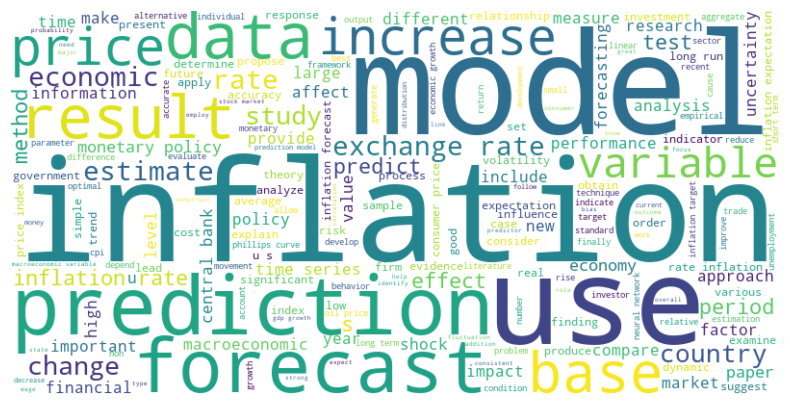

In [50]:
text_data = df["stop_removed"]

combined_string = " ".join(text_data)

wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color="white", 
    colormap="viridis"
).generate(combined_string)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [51]:
from collections import Counter

word_counts = Counter(
    " ".join(df["stop_removed"]).split()
)

word_freq = pd.DataFrame(
    word_counts.items(),
    columns=["word", "frequency"]
).sort_values(
    "frequency",
    ascending=False
)

display(word_freq.head(20))

,word,frequency
3,inflation,2816
38,model,2308
4,rate,1541
53,prediction,1403
14,price,1314
10,use,1213
31,forecast,1155
49,data,842
89,result,688
12,policy,680


In [52]:
print("Number of abstracts:", len(df))
print("Total words before preprocessing:",
      df["clean_Abstract"].str.split().str.len().sum())
print("Total words after preprocessing:",
      df["stop_removed"].str.split().str.len().sum())

Number of abstracts: 1125
Total words before preprocessing: 197871
Total words after preprocessing: 115867


### 1.2 Identify data columns relevant for feature engineering

The **`stop_removed`** column was selected as the main column for feature engineering because it contains the preprocessed research abstracts after cleaning, lemmatisation and removal of English stop words.

**TF-IDF (Term Frequency–Inverse Document Frequency)** was selected as the feature modelling technique. The `stop_removed` text was transformed into numerical TF-IDF features using both unigrams and bigrams. A maximum of 500 features was selected to control the dimensionality of the resulting feature matrix.

The relevant columns in the preprocessing pipeline are:

* **`Abstract`** – original research abstract.
* **`clean_Abstract`** – cleaned text with punctuation and unnecessary whitespace removed.
* **`text_lemmatized`** – text converted to its lemma/base-word forms.
* **`stop_removed`** – final preprocessed text used as the input for feature engineering.

The resulting TF-IDF matrix provides numerical features that can subsequently be used as input for machine-learning models or other analytical techniques.


In [53]:
# Feature Engineering using TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

# Use the preprocessed text
tfidf_vectorizer = TfidfVectorizer(
    max_features=500,
    ngram_range=(1, 2),
    min_df=2
)

# Transform the abstracts into numerical features
tfidf_features = tfidf_vectorizer.fit_transform(df["stop_removed"])

# Convert TF-IDF features into a DataFrame
tfidf_df = pd.DataFrame(
    tfidf_features.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=df.index
)

# Display the generated features
display(tfidf_df.head())

print("Number of abstracts:", tfidf_features.shape[0])
print("Number of engineered features:", tfidf_features.shape[1])

,10,19,2008,2021,ability,accord,account,accuracy,accurate,achieve,...,view,volatility,wage,way,weight,work,world,year,yield,zero
0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.075056,0.0,0.0,...,0.0,0.00000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
1,0.0,0.000000,0.0,0.000000,0.125417,0.0,0.0,0.101936,0.0,0.0,...,0.0,0.00000,0.0,0.000000,0.275885,0.0,0.0,0.0,0.120165,0.0
2,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.08743,0.0,0.000000,0.000000,0.0,0.0,0.0,0.092771,0.0
3,0.0,0.252049,0.0,0.602186,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.00000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
4,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.00000,0.0,0.092903,0.000000,0.0,0.0,0.0,0.000000,0.0


Number of abstracts: 1125
Number of engineered features: 500


### 1.2 Identify data columns relevant for feature engineering using feature modelling techniques

The **`stop_removed`** column was selected for feature engineering because it contains the preprocessed research abstracts after cleaning, lemmatisation and removal of stop words. The original **`Abstract`** column and intermediate columns such as **`clean_Abstract`** and **`text_lemmatized`** were retained as part of the preprocessing pipeline.

**TF-IDF (Term Frequency–Inverse Document Frequency)** was used as the feature modelling technique. TF-IDF was applied to the `stop_removed` column using unigrams and bigrams, with a maximum of 500 features.

The implementation produced:

* **Number of abstracts:** 1,125
* **Number of engineered features:** 500
* **Feature matrix:** 1,125 × 500

Each column in the resulting matrix represents a textual feature/term, such as `ability`, `accuracy`, `account`, `volatility`, `work`, and `yield`. The numerical values represent the TF-IDF importance of each term within an abstract. A value of **0** indicates that the corresponding feature does not contribute to that particular abstract, while larger values indicate greater importance.

Therefore, the **500 TF-IDF features** provide a numerical representation of the original textual data and can be used as input features for subsequent machine-learning modelling.


Training samples: 900
Testing samples: 225
Number of features: 500


,Clusters,Train Silhouette,Test Silhouette,Generalization Gap,Training Inertia
0,2,0.016293,0.018545,-0.002252,801.710414
1,3,0.017790,0.018065,-0.000275,790.112327
2,4,0.017984,0.017552,0.000432,780.325788
3,5,0.019397,0.020362,-0.000965,772.640897
4,6,0.019658,0.018570,0.001088,764.859143
5,7,0.022462,0.015249,0.007213,758.025997
6,8,0.022741,0.014564,0.008177,751.386134


Selected number of clusters: 5

===== BASELINE MODEL PERFORMANCE =====
Number of clusters: 5
Training silhouette score: 0.0194
Test silhouette score: 0.0204
Generalization gap: -0.001
Training inertia: 772.6409


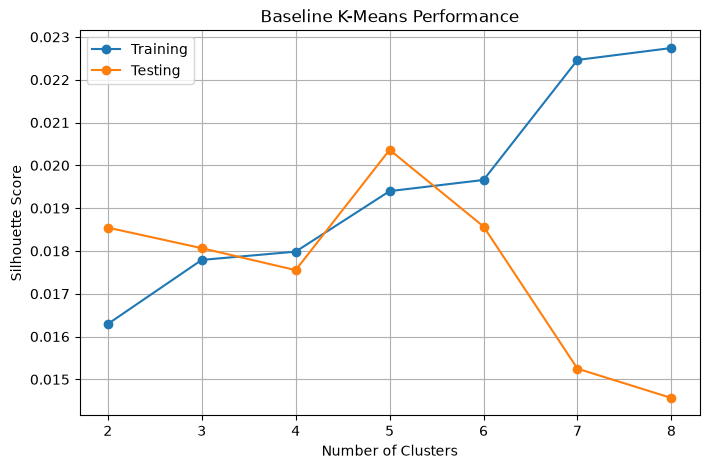

In [ ]:
# ============================================================
# 1.3 BASELINE MODEL
# K-Means clustering using TF-IDF features
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ------------------------------------------------------------
# Train-test split
# ------------------------------------------------------------
# X_tfidf is the TF-IDF matrix created in Section 1.2
# It should have shape: (1125, 500)

X_tfidf = tfidf_features

X_train, X_test = train_test_split(
    X_tfidf,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])


# ------------------------------------------------------------
# Test different numbers of clusters
# ------------------------------------------------------------

cluster_results = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Train the model
    train_labels = kmeans.fit_predict(X_train)

    # Predict clusters for unseen test data
    test_labels = kmeans.predict(X_test)

    # Training performance
    train_silhouette = silhouette_score(
        X_train,
        train_labels
    )

    # Generalization performance
    test_silhouette = silhouette_score(
        X_test,
        test_labels
    )

    cluster_results.append({
        "Clusters": k,
        "Train Silhouette": train_silhouette,
        "Test Silhouette": test_silhouette,
        "Generalization Gap": (
            train_silhouette - test_silhouette
        ),
        "Training Inertia": kmeans.inertia_
    })


# ------------------------------------------------------------
# Performance report
# ------------------------------------------------------------

results_df = pd.DataFrame(cluster_results)

display(results_df)


# ------------------------------------------------------------
# Select the baseline model
# ------------------------------------------------------------

best_k = results_df.loc[
    results_df["Test Silhouette"].idxmax(),
    "Clusters"
]

print("Selected number of clusters:", best_k)


# ------------------------------------------------------------
# Train final baseline model
# ------------------------------------------------------------

baseline_model = KMeans(
    n_clusters=int(best_k),
    random_state=42,
    n_init=10
)

train_clusters = baseline_model.fit_predict(X_train)
test_clusters = baseline_model.predict(X_test)


# ------------------------------------------------------------
# Final performance metrics
# ------------------------------------------------------------

final_train_silhouette = silhouette_score(
    X_train,
    train_clusters
)

final_test_silhouette = silhouette_score(
    X_test,
    test_clusters
)

generalization_gap = (
    final_train_silhouette -
    final_test_silhouette
)

print("\n===== BASELINE MODEL PERFORMANCE =====")
print("Number of clusters:", best_k)
print("Training silhouette score:",
      round(final_train_silhouette, 4))
print("Test silhouette score:",
      round(final_test_silhouette, 4))
print("Generalization gap:",
      round(generalization_gap, 4))
print("Training inertia:",
      round(baseline_model.inertia_, 4))


# ------------------------------------------------------------
# Plot silhouette performance
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Clusters"],
    results_df["Train Silhouette"],
    marker="o",
    label="Training"
)

plt.plot(
    results_df["Clusters"],
    results_df["Test Silhouette"],
    marker="o",
    label="Testing"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Baseline K-Means Performance")
plt.legend()
plt.grid(True)

plt.show()